# MNIST — tuned introductory CNN

Train a small CNN with two convolution/pooling stages. This keeps the architecture within the assignment's introductory-CNN scope: no pretrained network or deep backbone.

All three project notebooks use the same stratified 50,000/10,000 development split and untouched 10,000-image test set. Run all cells in a fresh runtime. No old scores are retained as new results. TensorFlow, scikit-learn, NumPy, pandas, and matplotlib are required; Colab normally includes them. MNIST downloads on first use.

Exports: `models/cnn_final.keras`, metadata, tuning CSV, learning curves, test metrics, and error-analysis plots. Model selection is automatic from validation evidence rather than hardcoded to experiment B. The duplicate preliminary A training from the original notebook has been removed.


In [1]:
import json
import os
import platform
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import mnist
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

# Render saved figures inline when executed in a notebook kernel.
from IPython import get_ipython
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

# Allocate GPU memory as needed rather than reserving the entire device.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

if os.environ.get('MNIST_REQUIRE_GPU') == '1' and not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Local GPU training requested, but TensorFlow cannot see a GPU.')

SEED = 42
keras.utils.set_random_seed(SEED)  # Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()

# Works when launched from the repository root or its notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
MODEL_DIR = PROJECT_ROOT / 'models'
CHECKPOINT_DIR = MODEL_DIR / 'cnn_checkpoints'
RESULT_DIR = PROJECT_ROOT / 'results' / 'cnn'
for folder in (MODEL_DIR, CHECKPOINT_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

environment = {
    'python': sys.version.split()[0],
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'scikit-learn': sklearn.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'matplotlib': plt.matplotlib.__version__,
    'platform': platform.platform(),
    'gpu_devices': [d.name for d in tf.config.list_physical_devices('GPU')],
    'gpu_details': [tf.config.experimental.get_device_details(d) for d in tf.config.list_physical_devices('GPU')],
    'logical_cpus': os.cpu_count(),
    'processor': platform.processor(),
}
print(json.dumps(environment, indent=2))
print('Project directory:', PROJECT_ROOT)


I0000 00:00:1791672511.465522   10621 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791672512.867442   10621 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{
  "python": "3.12.3",
  "tensorflow": "2.21.0",
  "keras": "3.15.1",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "matplotlib": "3.11.2",
  "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39",
  "gpu_devices": [
    "/physical_device:GPU:0"
  ],
  "gpu_details": [
    {
      "compute_capability": [
        8,
        9
      ],
      "device_name": "NVIDIA GeForce RTX 4060 Laptop GPU"
    }
  ],
  "logical_cpus": 20,
  "processor": "x86_64"
}
Project directory: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1


## 1. Shared data preparation

Load MNIST and split the 60,000 development images with `test_size=10000`, `random_state=42`, and `stratify=y_train_full`, exactly as in the MLP and Random Forest notebooks.

Cast raw pixels to `float32`, divide by 255, and add one grayscale channel. CNN input has shape `(N,28,28,1)`; unlike MLP/RF, the spatial grid is retained. Labels remain integer classes for sparse categorical cross-entropy. The test set is prepared here but not scored during tuning.


In [2]:
(X_train_full, y_train_full), (X_test_raw, y_test) = mnist.load_data()
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=10000, random_state=SEED, stratify=y_train_full,
)

def prepare_cnn_images(images):
    """For raw MNIST arrays (N, 28, 28), return float32 inputs (N, 28, 28, 1)."""
    images = np.asarray(images)
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        raise ValueError('Expected raw MNIST images with shape (N, 28, 28).')
    return (images.astype('float32') / 255.0).reshape(len(images), 28, 28, 1)

X_train = prepare_cnn_images(X_train_raw)
X_val = prepare_cnn_images(X_val_raw)
X_test = prepare_cnn_images(X_test_raw)

assert X_train.shape == (50000, 28, 28, 1)
assert X_val.shape == (10000, 28, 28, 1)
assert X_test.shape == (10000, 28, 28, 1)
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() <= X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(10))
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Training label counts:', np.bincount(y_train))


Train: (50000, 28, 28, 1) Validation: (10000, 28, 28, 1) Test: (10000, 28, 28, 1)
Training label counts: [4936 5618 4965 5109 4868 4518 4932 5221 4876 4957]


## 2. Planned CNN experiments

| Trial | Conv filters | Learning rate | Batch size | Dense units | Question |
|---|---|---|---|---|---|
| A | 16, 32 | 0.001 | 128 | 64 | Baseline |
| B | 32, 64 | 0.001 | 128 | 64 | Does more convolutional capacity help? |
| C | 16, 32 | 0.0003 | 128 | 64 | Does a smaller learning rate help? |

Each trial uses fresh weights and the same seed, data, and stopping policy: at most 20 epochs, patience 3. Within each trial, save the checkpoint with minimum validation loss. Select the checkpoint with highest validation accuracy, then lower validation loss and fewer parameters to break ties. Set this policy before looking at results. The search is small and controlled, not exhaustive.

The original first checkpoint callback omitted `save_best_only=True`. This notebook consistently uses best-only checkpoints for every trial.


In [3]:
MAX_EPOCHS = 20
PATIENCE = 3
EXPERIMENTS = [
    {'name': 'A', 'filters': [16, 32], 'learning_rate': 0.001, 'batch_size': 128, 'dense_units': 64},
    {'name': 'B', 'filters': [32, 64], 'learning_rate': 0.001, 'batch_size': 128, 'dense_units': 64},
    {'name': 'C', 'filters': [16, 32], 'learning_rate': 0.0003, 'batch_size': 128, 'dense_units': 64},
]

def build_cnn(filters, learning_rate, dense_units):
    model = keras.Sequential([  # Sequential = layers stacked in order
        keras.Input(shape=(28, 28, 1)),  # input: 28x28 grayscale image
        layers.Conv2D(filters[0], (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),  # keep the max of each 2x2 block
        layers.Conv2D(filters[1], (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),  # keep the max of each 2x2 block
        layers.Flatten(),  # feature maps -> one long row
        layers.Dense(dense_units, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ], name='mnist_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'],
    )
    return model

preview = build_cnn([16, 32], learning_rate=0.001, dense_units=64)
preview.summary()
del preview


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
trial_results = []
histories = {}  # will hold the loss curves for each experiment

def run_cnn(config):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_cnn(config['filters'], config['learning_rate'], config['dense_units'])
    checkpoint_path = CHECKPOINT_DIR / f"cnn_{config['name']}.keras"
    # Prevent a checkpoint from an earlier run being mistaken for this trial.
    if checkpoint_path.exists():
        checkpoint_path.unlink()
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(checkpoint_path), monitor='val_loss', mode='min', save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_loss', mode='min', patience=PATIENCE,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS, batch_size=config['batch_size'],
        callbacks=callbacks, verbose=2, shuffle=True,
    )
    train_seconds = time.perf_counter() - start
    values = history.history
    if not all(np.isfinite(values[key]).all() for key in ('loss', 'val_loss', 'accuracy', 'val_accuracy')):
        raise RuntimeError(f"Trial {config['name']} produced non-finite metrics; investigate before selecting a model.")
    if not checkpoint_path.exists():
        raise RuntimeError(f"No checkpoint saved for trial {config['name']}.")
    best_index = int(np.argmin(values['val_loss']))
    # Verify the metrics of the actual file that will be considered for deployment.
    saved_model = keras.models.load_model(checkpoint_path)
    val_loss, val_accuracy = saved_model.evaluate(X_val, y_val, verbose=0)
    row = {
        **config,
        'best_epoch': best_index + 1,
        'epochs_run': len(values['loss']),
        'val_loss': float(val_loss),
        'val_accuracy': float(val_accuracy),
        'train_accuracy_at_best_epoch': float(values['accuracy'][best_index]),
        'train_seconds': float(train_seconds),
        'parameters': int(saved_model.count_params()),
        'checkpoint': str(checkpoint_path.relative_to(PROJECT_ROOT)),
    }
    pd.DataFrame(values).rename_axis('epoch_index').to_csv(RESULT_DIR / f"history_{config['name']}.csv")
    histories[config['name']] = values
    print(f"Trial {config['name']}: best epoch {row['best_epoch']}, validation accuracy {val_accuracy:.4%}, training {train_seconds:.1f}s")
    return row

for config in EXPERIMENTS:
    trial_results.append(run_cnn(config))
    pd.DataFrame(trial_results).to_csv(RESULT_DIR / 'tuning_results_partial.csv', index=False)

results = pd.DataFrame(trial_results)
results.to_csv(RESULT_DIR / 'tuning_results.csv', index=False)
print(results[['name', 'filters', 'learning_rate', 'batch_size', 'dense_units',
               'best_epoch', 'epochs_run', 'val_accuracy', 'val_loss', 'train_seconds', 'parameters']].to_string(index=False))


Epoch 1/20


E0000 00:00:1791672515.450154   10621 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1791672523.361941   10621 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


391/391 - 9s - 22ms/step - accuracy: 0.9029 - loss: 0.3434 - val_accuracy: 0.9676 - val_loss: 0.1103


Epoch 2/20


...

391/391 - 5s - 13ms/step - accuracy: 0.9928 - loss: 0.0258 - val_accuracy: 0.9860 - val_loss: 0.0505


Epoch 20/20


391/391 - 5s - 12ms/step - accuracy: 0.9935 - loss: 0.0242 - val_accuracy: 0.9863 - val_loss: 0.0503


E0000 00:00:1791672733.349817   10621 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Trial C: best epoch 20, validation accuracy 98.6300%, training 107.5s
name  filters  learning_rate  batch_size  dense_units  best_epoch  epochs_run  val_accuracy  val_loss  train_seconds  parameters
   A [16, 32]         0.0010         128           64           6           9        0.9857  0.049130      50.399840       56714
   B [32, 64]         0.0010         128           64           7          10        0.9874  0.044602      54.910557      121930
   C [16, 32]         0.0003         128           64          20          20        0.9863  0.050316     107.500339       56714


## 3. Learning curves and automatic selection

Use training/validation loss and accuracy to discuss generalization and the selected epoch. A widening gap or rising validation loss can indicate overfitting. The final model is the selected saved checkpoint; it is not the last epoch's weights and the winner is not assumed in advance. One seed per setting is a limited experiment; repeat close results with additional seeds if time permits.


**Team study notes — restored from the original notebook.**



#  plot the loss curves

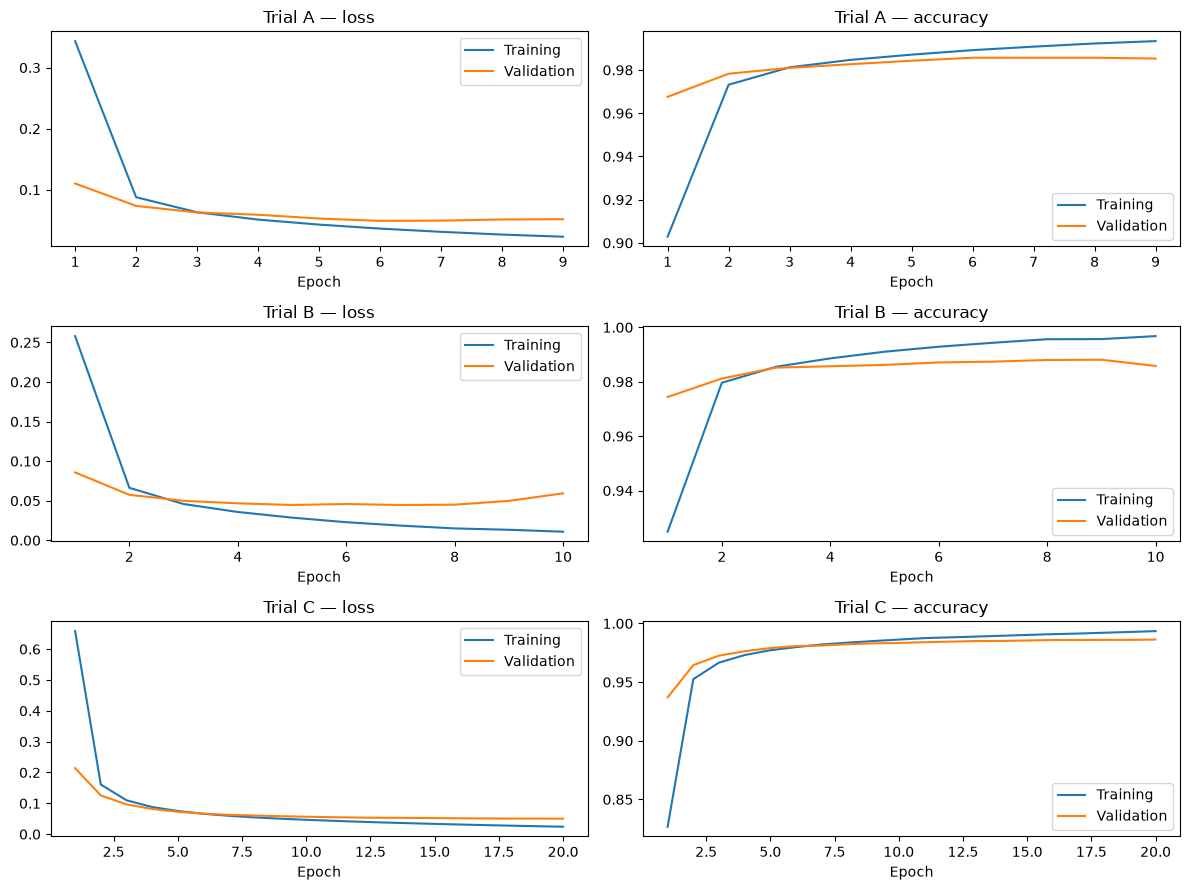

Chosen trial: B
Convolution filters: [32, 64] Dense units: 64
Learning rate: 0.001 Batch size: 128
Selected epoch: 7 Validation accuracy: 0.9873999953269958
Saved model: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/models/cnn_final.keras


In [5]:
fig, axes = plt.subplots(len(EXPERIMENTS), 2, figsize=(12, 3 * len(EXPERIMENTS)))
for row, config in enumerate(EXPERIMENTS):
    h = histories[config['name']]
    epochs = np.arange(1, len(h['loss']) + 1)
    axes[row, 0].plot(epochs, h['loss'], label='Training')
    axes[row, 0].plot(epochs, h['val_loss'], label='Validation')
    axes[row, 0].set_title(f"Trial {config['name']} — loss")
    axes[row, 1].plot(epochs, h['accuracy'], label='Training')
    axes[row, 1].plot(epochs, h['val_accuracy'], label='Validation')
    axes[row, 1].set_title(f"Trial {config['name']} — accuracy")
    for ax in axes[row]:
        ax.set_xlabel('Epoch')
        ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / 'learning_curves.png', dpi=150)
plt.show()

ranked = results.sort_values(
    ['val_accuracy', 'val_loss', 'parameters', 'name'],
    ascending=[False, True, True, True],
)
winner = ranked.iloc[0].to_dict()
FINAL_PATH = MODEL_DIR / 'cnn_final.keras'
# Copy the exact selected checkpoint; do not retrain on the test set.
shutil.copy2(PROJECT_ROOT / winner['checkpoint'], FINAL_PATH)
print('Chosen trial:', winner['name'])
print('Convolution filters:', winner['filters'], 'Dense units:', winner['dense_units'])
print('Learning rate:', winner['learning_rate'], 'Batch size:', winner['batch_size'])
print('Selected epoch:', winner['best_epoch'], 'Validation accuracy:', winner['val_accuracy'])
print('Saved model:', FINAL_PATH)


## 4. Test evaluation of the saved model

Evaluate only the selected checkpoint on the test set, after tuning is finished. Export accuracy, macro precision/recall/F1, per-digit metrics, confusion matrix, and misclassified examples. Do not choose a new trial based on its test score.

Inference time is a 10,000-image batch after warm-up and excludes loading. It is not the app's single-drawing latency. Record hardware and package versions when comparing against RF/MLP; their training times are meaningful only with that context.


In [6]:
keras.backend.clear_session()
load_start = time.perf_counter()
cnn_loaded = keras.models.load_model(FINAL_PATH)
load_seconds = time.perf_counter() - load_start

# Warm up using validation data, leaving test evaluation to the next prediction.
_ = cnn_loaded.predict(X_val[:128], batch_size=128, verbose=0)
start = time.perf_counter()
test_probs = cnn_loaded.predict(X_test, batch_size=128, verbose=0)
inference_seconds = time.perf_counter() - start
assert test_probs.shape == (10000, 10)
assert np.isfinite(test_probs).all()
assert np.allclose(test_probs.sum(axis=1), 1.0, atol=1e-5)
test_pred = np.argmax(test_probs, axis=1)  # the digit with the highest probability
test_accuracy = float(accuracy_score(y_test, test_pred))
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, test_pred, average='macro', zero_division=0,
)
# Predictive cross-entropy excludes any L2 weight penalty.
true_class_probs = test_probs[np.arange(len(y_test)), y_test]
test_crossentropy = float(-np.log(np.clip(true_class_probs, 1e-7, 1.0)).mean())
report = classification_report(y_test, test_pred, labels=list(range(10)), output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, test_pred, labels=list(range(10)))

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Macro F1: {macro_f1:.4f}')
print(f'Predictive cross-entropy: {test_crossentropy:.4f}')
print(f'Model size: {FINAL_PATH.stat().st_size / (1024 ** 2):.2f} MiB')
print(f'Loading: {load_seconds:.2f}s; 10,000 predictions after warm-up: {inference_seconds:.2f}s')
print(classification_report(y_test, test_pred, labels=list(range(10)), digits=4, zero_division=0))
pd.DataFrame(report).T.to_csv(RESULT_DIR / 'classification_report.csv')
pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv(RESULT_DIR / 'confusion_matrix.csv')


Test accuracy: 99.0200%
Macro F1: 0.9901
Predictive cross-entropy: 0.0310
Model size: 1.43 MiB
Loading: 0.23s; 10,000 predictions after warm-up: 0.72s
              precision    recall  f1-score   support

           0     0.9979    0.9816    0.9897       980
           1     0.9921    0.9991    0.9956      1135
           2     0.9932    0.9893    0.9913      1032
           3     0.9930    0.9901    0.9916      1010
           4     0.9929    0.9929    0.9929       982
           5     0.9822    0.9877    0.9849       892
           6     0.9855    0.9948    0.9901       958
           7     0.9827    0.9922    0.9874      1028
           8     0.9948    0.9856    0.9902       974
           9     0.9871    0.9871    0.9871      1009

    accuracy                         0.9902     10000
   macro avg     0.9901    0.9900    0.9901     10000
weighted avg     0.9902    0.9902    0.9902     10000



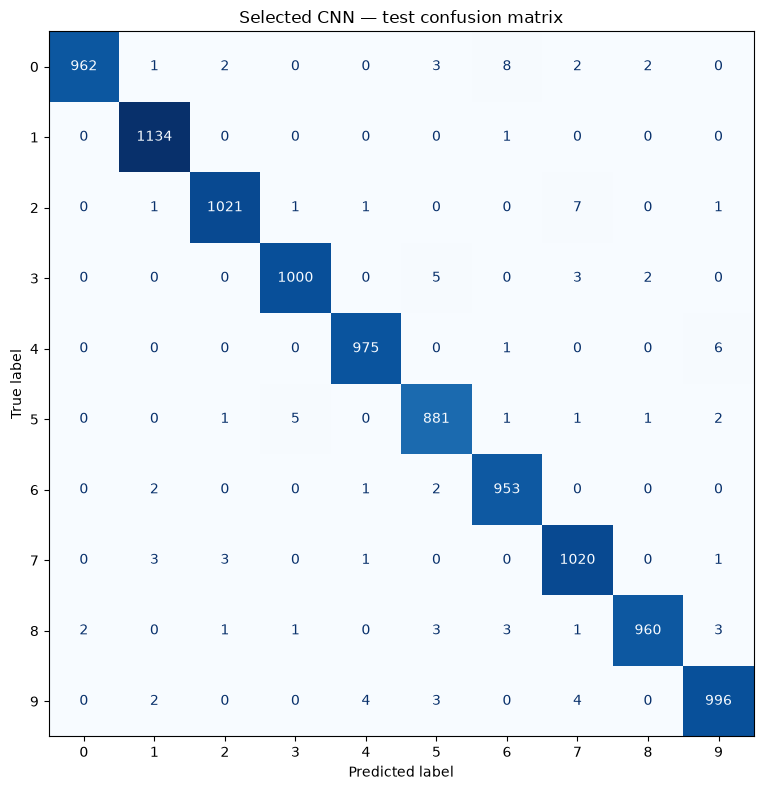

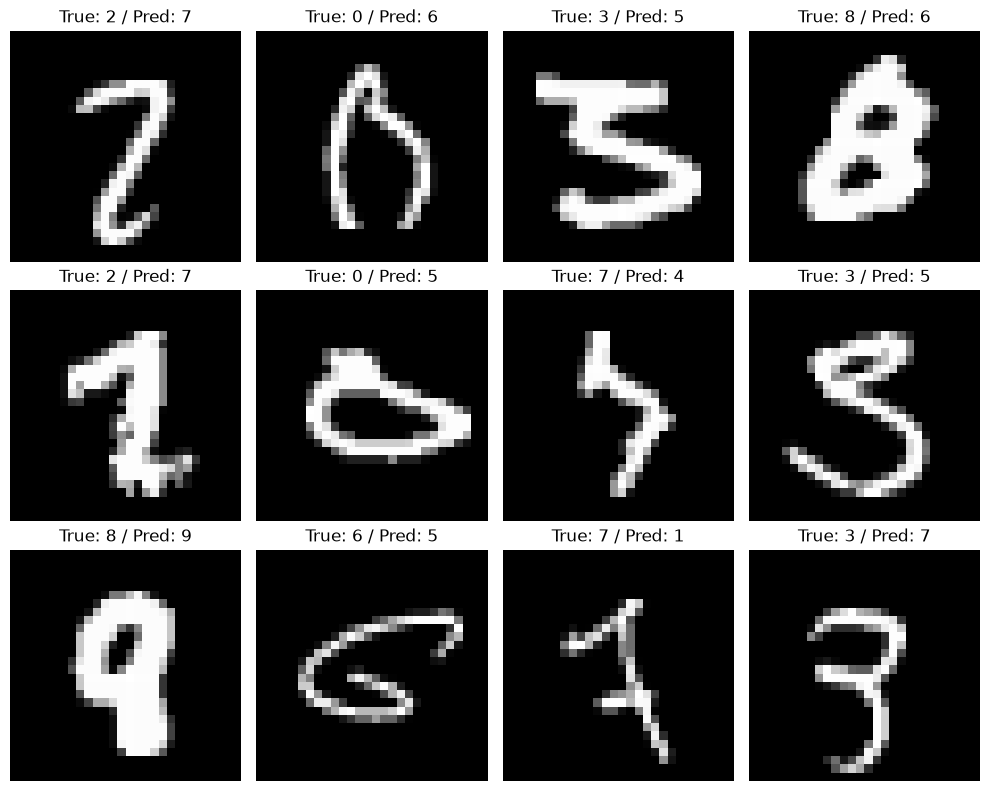

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Selected CNN — test confusion matrix')
fig.tight_layout()
fig.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

wrong = np.flatnonzero(test_pred != y_test)[:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, wrong):
        ax.imshow(X_test_raw[index], cmap='gray')
        ax.set_title(f'True: {y_test[index]} / Pred: {test_pred[index]}')
    fig.tight_layout()
    fig.savefig(RESULT_DIR / 'misclassified_examples.png', dpi=150)
    plt.show()
else:
    print('No test errors in this run.')


## 5. Check saving/reloading and export the experiment record

Compare predictions from two independent loads on validation samples. The full test predictions above already came from the saved final model. Save preprocessing and environment details beside the model so the app can reproduce its expected inputs.


In [8]:
second_load = keras.models.load_model(FINAL_PATH, compile=False)
validation_probs_1 = cnn_loaded.predict(X_val[:32], verbose=0)
validation_probs_2 = second_load.predict(X_val[:32], verbose=0)
np.testing.assert_allclose(validation_probs_1, validation_probs_2, rtol=1e-5, atol=1e-6)
assert second_load.input_shape == (None, 28, 28, 1)
assert second_load.output_shape == (None, 10)
del second_load
print('Reload check passed; input (N, 28, 28, 1), output (N, 10).')

metrics = {
    'model': 'CNN',
    'selected_trial': str(winner['name']),
    'best_epoch': int(winner['best_epoch']),
    'validation_accuracy': float(winner['val_accuracy']),
    'test_accuracy': test_accuracy,
    'test_predictive_crossentropy': test_crossentropy,
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1),
    'parameters': int(cnn_loaded.count_params()),
    'selected_trial_train_seconds': float(winner['train_seconds']),
    'total_search_train_seconds': float(results['train_seconds'].sum()),
    'load_seconds': float(load_seconds),
    'test_inference_seconds_10000_after_warmup': float(inference_seconds),
    'file_size_mib': FINAL_PATH.stat().st_size / (1024 ** 2),
}
metadata = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'MNIST',
    'split': {'train': 50000, 'validation': 10000, 'test': 10000,
              'random_state': SEED, 'stratify': True},
    'preprocessing': {'input_shape': [28, 28, 1], 'dtype': 'float32',
                      'normalization': 'raw pixel / 255.0',
                      'polarity': 'bright digit on dark background',
                      'labels': 'integer digits 0-9'},
    'selection': 'Highest validation accuracy at each trial minimum-val-loss checkpoint; tie: lower val_loss, fewer parameters, trial name',
    'hyperparameters': next(c for c in EXPERIMENTS if c['name'] == winner['name']),
    'training': {'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'seed': SEED},
    'environment': environment,
    'metrics': metrics,
}
(MODEL_DIR / 'cnn_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(RESULT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
pd.DataFrame([metrics]).to_csv(RESULT_DIR / 'comparison_row.csv', index=False)
(RESULT_DIR / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))


Reload check passed; input (N, 28, 28, 1), output (N, 10).
{
  "model": "CNN",
  "selected_trial": "B",
  "best_epoch": 7,
  "validation_accuracy": 0.9873999953269958,
  "test_accuracy": 0.9902,
  "test_predictive_crossentropy": 0.03095587156713009,
  "macro_precision": 0.9901440874009652,
  "macro_recall": 0.9900472474739612,
  "macro_f1": 0.9900797612017815,
  "parameters": 121930,
  "selected_trial_train_seconds": 54.91055674800009,
  "total_search_train_seconds": 212.81073538000055,
  "load_seconds": 0.23359944399999222,
  "test_inference_seconds_10000_after_warmup": 0.7176645050003572,
  "file_size_mib": 1.4312591552734375
}


## 6. Conclusions and app contract

After running, describe the selected filters, learning rate, epoch, and validation accuracy. Compare A/B/C to explain whether added capacity or the smaller learning rate helped. Use the learning curves and per-digit errors to discuss generalization. Fill the shared report with measured values rather than copying old scores: the original 99.01% result does not describe this rerun automatically.

Load `models/cnn_final.keras` with `keras.models.load_model(path, compile=False)`. For a single drawing, supply `float32` input of shape **(1,28,28,1)** in [0,1], with a bright digit on a dark background. Obtain the digit with `argmax` of the ten output scores.

The future drawing app needs grayscale conversion, content crop, aspect-ratio-preserving resize, centering in a 28×28 image, blank-input rejection, and a processed preview. Do not divide an already-normalized drawing by 255 again. The required app is a separate project step; picture upload remains a later extension after documentation.


## 7. Optional Colab download

The next cell creates a ZIP containing the final model, metadata, and this run's result files (excluding experiment checkpoints). In Colab it downloads the ZIP. Outside Colab it prints its location. Keep only the three final models in the eventual deployment repository; intermediate tuning checkpoints are not required app assets.


In [9]:
import zipfile

archive_path = PROJECT_ROOT / 'cnn_deliverables.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in [FINAL_PATH, MODEL_DIR / 'cnn_metadata.json', *sorted(RESULT_DIR.glob('*'))]:
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(PROJECT_ROOT)))
print('Deliverables ZIP:', archive_path)
try:
    from google.colab import files
except ImportError:
    print('Local environment: retrieve the ZIP from the path above.')
else:
    files.download(str(archive_path))


Deliverables ZIP: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/cnn_deliverables.zip
Local environment: retrieve the ZIP from the path above.


## Original code comments retained for study

These verbatim excerpts preserve comments attached to code that changed during correction. They are historical study material; run the corrected executable cells above. NumPy-only seeding does not seed all TensorFlow randomness, and MNIST may download on first use.

Original code cell 3:

```python
# Split off 10,000 for validation (same call as the whole team)
```

Original code cell 4:

```python
# Normalize to 0-1
```

Original code cell 5:

```python
# CNN shape: add a channel dimension (28, 28, 1)
```

Original code cell 7:

```python
        layers.Conv2D(filters1, (3, 3), activation="relu"),      # stage 1: slide 3x3 filters, ReLU
        layers.Conv2D(filters2, (3, 3), activation="relu"),      # stage 2
        layers.Dense(64, activation="relu"),                     # fully connected layer, 64 neurons
        layers.Dense(10, activation="softmax"),                  # 10 outputs: one probability per digit
model = build_cnn(16, 32)    # experiment A: 16 filters, then 32
model.summary()              # print the layers, output shapes and parameter counts
```

Original code cell 8:

```python
# 1. Compile: tell Keras how to learn
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # is the loss for multi-class problems. "Sparse" means our labels are plain numbers (0–9)
    loss="sparse_categorical_crossentropy",                  # how wrong the probabilities are
    metrics=["accuracy"]                                     # also report % correct
# 2. Checkpoint: save the model whenever validation loss reaches a new low
    "cnn_A.keras",           # file to write
    monitor="val_loss",      # watch the validation loss
```

Original code cell 9:

```python
# 3. Train
    X_train_cnn, y_train,                     # learn from the 50,000 training images
    validation_data=(X_val_cnn, y_val),       # measure (but not learn from) the 10,000 validation images
    epochs=10,                                # up to 10 passes over the training data
    batch_size=128,                           # adjust the weights after every 128 images
    callbacks=[checkpoint]                    # run the checkpoint after each epoch
```

Original code cell 10:

```python
results = {}     # will hold the numbers for each experiment
    keras.utils.set_random_seed(42)                 # fix the randomness so results can be repeated
    model = build_cnn(filters1, filters2)           # the same recipe as before
        verbose=0                                   # don't print every epoch (we'll print a summary)
    best_epoch = int(np.argmin(history.history["val_loss"]))      # index of the lowest validation loss
    best_val_acc = history.history["val_accuracy"][best_epoch]     # validation accuracy at that epoch
```

Original code cell 12:

```python
fig, axes = plt.subplots(1, 3, figsize=(15, 4))      # 3 plots side by side
    ax.plot(h["loss"], label="training loss")          # how wrong on the images it learns from
    ax.plot(h["val_loss"], label="validation loss")    # how wrong on the unseen validation images
```

Original code cell 13:

```python
# 1. Load the BEST checkpoint of experiment B (epoch 7), not the model as it ended
# 2. Score it on the sealed test set (first time we touch it)
test_probs = best_cnn.predict(X_test_cnn, verbose=0)    # 10,000 rows of 10 probabilities
test_acc = (test_pred == y_test).mean()                 # share of correct predictions
# 3. Save it under the final name and check the size
```
